# Proyek Sains Data - Klasifikasi Citra Penataan Sepatu (Rapi vs Berantakan)
## Ekstraksi 53 Fitur Multimodal dengan Data Augmentasi (1 Citra → 4 Sampel) & Pemodelan Ensemble Weighted Soft Voting

---

### Ringkasan Metodologi
1. **Data Augmentasi (1 citra → 4 sampel)**: `baseline` (asli), `rotate_15` (rotasi 15°), `flip_horizontal` (cermin), dan `adjust_brightness` (kecerahan/kontras $I' = 1{,}15\,I + 15$). Kolom `jenis_augmentasi` mencatat asal setiap sampel.
2. **53 fitur multimodal** (tanpa *neural network*):

| Kelompok | Jumlah | Fitur |
| :--- | :---: | :--- |
| Warna RGB (orde pertama) | 9 | `mean_*`, `std_*`, `skew_*` kanal R, G, B |
| Tekstur GLCM (orde kedua) | 5 | `energi`, `entropi`, `kontras`, `korelasi`, `homogenitas` |
| Warna HSV | 9 | `mean_*`, `std_*`, `skew_*` kanal H, S, V |
| Tepi | 4 | `edge_density`, `sobel_mean`, `sobel_std`, `laplacian_var` |
| Kontur & bentuk | 6 | `num_contours`, `contour_area_mean`, `contour_area_std`, `contour_solidity`, `hu_1`, `hu_2` |
| Orientasi gradien | 10 | `orient_bin0`–`orient_bin7`, `orient_entropi`, `orient_ortho` |
| Pita spasial | 5 | `band_atas`, `band_tengah`, `band_bawah`, `rasio_bawah_atas`, `rasio_tengah_atas` |
| Titik kunci ORB | 3 | `orb_total`, `orb_bawah`, `orb_rasio_bawah` |
| Tekstur LBP | 2 | `lbp_mean`, `lbp_std` |

3. **Weighted Soft Voting Ensemble**: SVM RBF (bobot 2) + Extra Trees (bobot 2) + Gradient Boosting (bobot 1).
4. **10-Fold Stratified Cross-Validation tanpa kebocoran data**: pembagian *fold* dilakukan pada **citra asli**. Augmentasi hanya ditambahkan ke data latih, sedangkan data validasi selalu citra asli (`baseline`) yang variasinya tidak pernah ikut dilatih.
5. **Optimalisasi ambang batas (*threshold tuning*)**, kurva ROC, penyimpanan model `.pkl`, fungsi prediksi citra baru, rekap evolusi akurasi, dan komparasi 12 metode.

Semua keluaran disimpan di folder **`hasil3/`**.

---
## Bagian 1: Ekstraksi 53 Fitur dengan Data Augmentasi (1 Citra → 4 Sampel)

### 1. Skema Transformasi Augmentasi
Setiap citra di-*resize* ke 256 × 256, lalu dibuat 4 variasi:
1. **`baseline`**: citra asli.
2. **`rotate_15`**: rotasi 15° dengan *border reflect*, meniru kamera yang dipegang miring.
3. **`flip_horizontal`**: pencerminan kiri-kanan, meniru rak dilihat dari sisi berlawanan; susunan rapi/berantakan tidak berubah.
4. **`adjust_brightness`**: $I' = 1{,}15 \times I + 15$, meniru perbedaan pencahayaan ruangan.

### 2. Teori Singkat Fitur
- **Orde pertama (RGB, HSV)**: $\mu = \frac{1}{MN}\sum C(i,j)$, $\sigma = \sqrt{\frac{1}{MN}\sum (C(i,j)-\mu)^2}$, *skewness* $= \frac{1}{MN}\sum\left(\frac{C(i,j)-\mu}{\sigma}\right)^3$.
- **GLCM** ($d = 1$, $\theta = 0^\circ$, 256 level, `symmetric=False`, `normed=True`): energi $\sum P^2$, entropi $-\sum P\log_2 P$, kontras $\sum (i-j)^2 P$, korelasi $\sum \frac{(i-\mu_i)(j-\mu_j)P}{\sigma_i\sigma_j}$, homogenitas $\sum \frac{P}{1+|i-j|}$.
- **Tepi**: kepadatan tepi Canny, besar gradien Sobel $\sqrt{G_x^2 + G_y^2}$, variansi Laplacian $\nabla^2 I$.
- **Kontur**: jumlah dan luas kontur, *solidity* $A / A_{\text{convex hull}}$, momen Hu.
- **Orientasi gradien**: histogram 8 arah $\theta = \arctan(G_y/G_x)$ berbobot besar gradien; `orient_ortho` = proporsi garis mendatar/tegak.
- **Pita spasial**: kepadatan tepi pada sepertiga atas, tengah, bawah citra.
- **ORB**: jumlah titik sudut, khususnya di bagian bawah (lantai).
- **LBP**: pola tekstur lokal 8 tetangga, radius 1.

### 3. Kolom Dataset yang Dihasilkan
`hasil3/fitur_augmentasi.csv`: `id_citra`, `nama_file`, `kelas`, `jenis_augmentasi`, 53 fitur.

In [1]:
import os

FOLDER_CITRA = "citra"
FOLDER_HASIL = "hasil3"
KELAS = ["rapi", "berantakan"]
EKSTENSI = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
UKURAN = (256, 256)
os.makedirs(FOLDER_HASIL, exist_ok=True)
print("Dataset :", os.path.abspath(FOLDER_CITRA))
print("Keluaran:", os.path.abspath(FOLDER_HASIL))

Dataset : c:\project\image-classification\citra
Keluaran: c:\project\image-classification\hasil3


In [2]:
import cv2
import numpy as np
from scipy.stats import skew
from skimage.feature import graycomatrix, local_binary_pattern

def baca_citra(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    return img

def preprocessing(img_bgr):
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    return cv2.resize(rgb, UKURAN, interpolation=cv2.INTER_AREA)

def augmentasi(rgb):
    h, w = rgb.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), 15, 1.0)
    return [("baseline", rgb),
            ("rotate_15", cv2.warpAffine(rgb, M, (w, h), borderMode=cv2.BORDER_REFLECT)),
            ("flip_horizontal", cv2.flip(rgb, 1)),
            ("adjust_brightness", cv2.convertScaleAbs(rgb, alpha=1.15, beta=15))]

def ke_gray(rgb):
    r, g, b = [rgb[:, :, i].astype(np.float64) for i in range(3)]
    return np.clip(np.round(0.299 * r + 0.587 * g + 0.114 * b), 0, 255).astype(np.uint8)

def momen(citra, nama):
    f = {}
    for stat, fungsi in [("mean", np.mean), ("std", np.std), ("skew", lambda x: skew(x.ravel()))]:
        for i, k in enumerate(nama):
            f[f"{stat}_{k}"] = float(fungsi(citra[:, :, i].astype(np.float64)))
    return f

def fitur_glcm(gray):
    P = graycomatrix(gray, distances=[1], angles=[0], levels=256, symmetric=False, normed=True)[:, :, 0, 0]
    i, j = np.indices(P.shape)
    nz = P[P > 0]
    mu_i, mu_j = np.sum(i * P), np.sum(j * P)
    sd_i, sd_j = np.sqrt(np.sum((i - mu_i) ** 2 * P)), np.sqrt(np.sum((j - mu_j) ** 2 * P))
    return {"energi": np.sum(P ** 2), "entropi": -np.sum(nz * np.log2(nz)),
            "kontras": np.sum((i - j) ** 2 * P),
            "korelasi": 1.0 if sd_i * sd_j == 0 else np.sum((i - mu_i) * (j - mu_j) * P) / (sd_i * sd_j),
            "homogenitas": np.sum(P / (1 + np.abs(i - j)))}

ORB = cv2.ORB_create(nfeatures=500)

def ekstrak_fitur(rgb):
    """53 fitur dari satu citra RGB 256x256."""
    gray = ke_gray(rgb)
    f = {**momen(rgb, "rgb"), **fitur_glcm(gray), **momen(cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV), "hsv")}

    # Tepi
    canny = cv2.Canny(gray, 50, 150)
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    f.update({"edge_density": (canny > 0).mean(), "sobel_mean": mag.mean(), "sobel_std": mag.std(),
              "laplacian_var": cv2.Laplacian(gray, cv2.CV_64F).var()})

    # Kontur & bentuk
    kontur, _ = cv2.findContours(canny, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    luas = np.array([cv2.contourArea(c) for c in kontur])
    besar = [c for c, a in zip(kontur, luas) if a > 10]
    solid = [cv2.contourArea(c) / cv2.contourArea(cv2.convexHull(c)) for c in besar if cv2.contourArea(cv2.convexHull(c)) > 0]
    hu = cv2.HuMoments(cv2.moments(canny, binaryImage=True)).ravel()
    f.update({"num_contours": len(kontur),
              "contour_area_mean": luas[luas > 10].mean() if besar else 0.0,
              "contour_area_std": luas[luas > 10].std() if besar else 0.0,
              "contour_solidity": np.mean(solid) if solid else 0.0,
              "hu_1": -np.sign(hu[0]) * np.log10(abs(hu[0]) + 1e-15),
              "hu_2": -np.sign(hu[1]) * np.log10(abs(hu[1]) + 1e-15)})

    # Orientasi gradien
    hist, _ = np.histogram(np.degrees(np.arctan2(gy, gx)) % 180, bins=8, range=(0, 180), weights=mag)
    h = hist / hist.sum() if hist.sum() > 0 else np.zeros(8)
    f.update({f"orient_bin{k}": v for k, v in enumerate(h)})
    f["orient_entropi"] = -np.sum(h[h > 0] * np.log2(h[h > 0]))
    f["orient_ortho"] = h[[0, 3, 4, 7]].sum()

    # Pita spasial
    t = canny > 0
    s = gray.shape[0] // 3
    atas, tengah, bawah = t[:s].mean(), t[s:2 * s].mean(), t[2 * s:].mean()
    f.update({"band_atas": atas, "band_tengah": tengah, "band_bawah": bawah,
              "rasio_bawah_atas": bawah / (atas + 1e-6), "rasio_tengah_atas": tengah / (atas + 1e-6)})

    # ORB
    titik = ORB.detect(gray, None)
    n_bawah = sum(1 for p in titik if p.pt[1] >= 2 * gray.shape[0] / 3)
    f.update({"orb_total": len(titik), "orb_bawah": n_bawah,
              "orb_rasio_bawah": n_bawah / len(titik) if titik else 0.0})

    # LBP
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    f.update({"lbp_mean": lbp.mean(), "lbp_std": lbp.std()})
    return {k: float(v) for k, v in f.items()}

print("Jumlah fitur per citra:", len(ekstrak_fitur(np.zeros((256, 256, 3), dtype=np.uint8) + 128)))

Jumlah fitur per citra: 53


C:\Users\Administrator\AppData\Local\Temp\ipykernel_11240\118542261.py:30: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  for stat, fungsi in [("mean", np.mean), ("std", np.std), ("skew", lambda x: skew(x.ravel()))]:


In [3]:
import os
import time
import pandas as pd

mulai = time.time()
baris = []
id_citra = 0
for kelas in KELAS:
    folder = os.path.join(FOLDER_CITRA, kelas)
    for nama in sorted(os.listdir(folder)):
        if not nama.lower().endswith(EKSTENSI):
            continue
        id_citra += 1
        rgb = preprocessing(baca_citra(os.path.join(folder, nama)))
        for jenis, varian in augmentasi(rgb):
            baris.append({"id_citra": id_citra, "nama_file": nama, "kelas": kelas,
                          "jenis_augmentasi": jenis, **ekstrak_fitur(varian)})

data = pd.DataFrame(baris)
FITUR = [c for c in data.columns if c not in ("id_citra", "nama_file", "kelas", "jenis_augmentasi")]
data.to_csv(os.path.join(FOLDER_HASIL, "fitur_augmentasi.csv"), index=False)

print("=" * 75)
print("INFORMASI DATASET HASIL DATA AUGMENTASI CITRA PENATAAN SEPATU")
print("=" * 75)
print(f"Citra asli            : {data['id_citra'].nunique()}")
print(f"Total sampel          : {len(data)} baris (4x lipat)")
print(f"Distribusi kelas      : {data['kelas'].value_counts().to_dict()}")
print(f"Distribusi augmentasi : {data['jenis_augmentasi'].value_counts().to_dict()}")
print(f"Jumlah fitur          : {len(FITUR)}")
print(f"Waktu ekstraksi       : {time.time() - mulai:.1f} detik")
print(f"Disimpan ke           : {FOLDER_HASIL}/fitur_augmentasi.csv")
data.head()

INFORMASI DATASET HASIL DATA AUGMENTASI CITRA PENATAAN SEPATU
Citra asli            : 194
Total sampel          : 776 baris (4x lipat)
Distribusi kelas      : {'rapi': 388, 'berantakan': 388}
Distribusi augmentasi : {'baseline': 194, 'rotate_15': 194, 'flip_horizontal': 194, 'adjust_brightness': 194}
Jumlah fitur          : 53
Waktu ekstraksi       : 56.2 detik
Disimpan ke           : hasil3/fitur_augmentasi.csv


,id_citra,nama_file,kelas,jenis_augmentasi,mean_r,mean_g,mean_b,std_r,std_g,std_b,...,band_atas,band_tengah,band_bawah,rasio_bawah_atas,rasio_tengah_atas,orb_total,orb_bawah,orb_rasio_bawah,lbp_mean,lbp_std
0,1,24-003 Rapi 2.jpg,rapi,baseline,167.527710,145.621918,129.198227,58.759761,58.723771,59.402692,...,0.236075,0.145221,0.099927,0.423284,0.615142,462.0,3.0,0.006494,5.121338,2.776685
1,1,24-003 Rapi 2.jpg,rapi,rotate_15,167.674042,146.795868,131.013016,56.974181,57.672339,58.145920,...,0.242325,0.120910,0.091842,0.379002,0.498955,464.0,3.0,0.006466,5.038300,2.541693
2,1,24-003 Rapi 2.jpg,rapi,flip_horizontal,167.527710,145.621918,129.198227,58.759761,58.723771,59.402692,...,0.235846,0.145267,0.100064,0.424274,0.615937,462.0,3.0,0.006494,5.121338,2.776685
3,1,24-003 Rapi 2.jpg,rapi,adjust_brightness,200.087418,178.358261,161.717636,58.692943,61.714209,65.404693,...,0.203355,0.139017,0.103470,0.508814,0.683612,462.0,4.0,0.008658,5.315262,2.751152
4,2,24-003 Rapi 3.jpg,rapi,baseline,151.797928,144.180862,136.961426,54.870804,62.468708,69.736436,...,0.162730,0.182445,0.101880,0.626067,1.121145,471.0,93.0,0.197452,5.032120,2.531152


---
## Bagian 2: Validasi Silang 10-Fold Stratified (Weighted Soft Voting) Tanpa Kebocoran

### 1. Protokol Validasi
Keempat variasi dari satu foto hampir identik. Jika variasi foto yang sama masuk ke data latih **dan** data validasi, model cukup mengenali foto yang sudah pernah dilihat, sehingga akurasi terlihat jauh lebih tinggi dari kemampuan sebenarnya. Karena itu:
1. **10-Fold Stratified K-Fold dilakukan pada citra asli** (bukan pada 4× sampel).
2. **Data latih** = 4 variasi dari citra-citra latih (augmentasi menambah variasi latih).
3. **Data validasi** = hanya citra asli (`baseline`) dari citra-citra validasi.
4. `StandardScaler` dipasang di dalam `Pipeline`, sehingga $z = (x-\mu)/\sigma$ hanya dihitung dari data latih setiap *fold*.

### 2. Arsitektur Weighted Soft Voting
| Model dasar | Parameter | Bobot |
| :--- | :--- | :---: |
| **SVM (RBF)** | $C = 10$, $\gamma$ = `scale`, `probability=True` | 2 |
| **Extra Trees** | 150 pohon, `max_features="log2"` | 2 |
| **Gradient Boosting** | 120 pohon, *learning rate* 0,08, kedalaman 4, *subsample* 0,75 | 1 |

Peluang akhir $P(\text{rapi}) = \frac{2P_{\text{SVM}} + 2P_{\text{ET}} + 1P_{\text{GB}}}{5}$; citra diprediksi **rapi** jika $P(\text{rapi}) \ge 0{,}5$.

In [4]:
import warnings
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)

def buat_ensemble():
    return make_pipeline(StandardScaler(), VotingClassifier(
        estimators=[("svm", SVC(kernel="rbf", C=10.0, gamma="scale", probability=True, random_state=42)),
                    ("et", ExtraTreesClassifier(n_estimators=150, max_features="log2", random_state=42)),
                    ("gb", GradientBoostingClassifier(n_estimators=120, learning_rate=0.08, max_depth=4,
                                                      subsample=0.75, random_state=42))],
        voting="soft", weights=[2.0, 2.0, 1.0]))

# Satu baris per citra asli untuk pembagian fold
asli = data[data["jenis_augmentasi"] == "baseline"].set_index("id_citra")
y_asli = (asli["kelas"] == "rapi").astype(int)
skf10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
FOLDS = list(skf10.split(asli.index, y_asli))

def validasi_silang(buat_model, fitur=FITUR, pakai_augmentasi=True, tampil=False):
    """10-fold CV pada citra asli. Mengembalikan log per fold dan peluang out-of-fold."""
    proba = pd.Series(np.nan, index=asli.index)
    log = []
    for k, (latih, val) in enumerate(FOLDS, 1):
        id_latih, id_val = asli.index[latih], asli.index[val]
        dl = data[data["id_citra"].isin(id_latih)]
        if not pakai_augmentasi:
            dl = dl[dl["jenis_augmentasi"] == "baseline"]
        dv = asli.loc[id_val]
        model = buat_model().fit(dl[fitur], (dl["kelas"] == "rapi").astype(int))
        yv = y_asli.loc[id_val]
        if hasattr(model, "predict_proba"):
            p = model.predict_proba(dv[fitur])[:, 1]
            proba.loc[id_val] = p
            pred = (p >= 0.5).astype(int)
        else:
            pred = model.predict(dv[fitur])
        log.append({"Fold": f"Fold {k}", "Latih": len(dl), "Validasi": len(dv),
                    "Akurasi": accuracy_score(yv, pred), "F1": f1_score(yv, pred, zero_division=0),
                    "Precision": precision_score(yv, pred, zero_division=0), "Recall": recall_score(yv, pred, zero_division=0)})
        if tampil:
            r = log[-1]
            print(f"[{r['Fold']:>7}] Latih: {r['Latih']} | Val: {r['Validasi']} -> Akurasi: {r['Akurasi']*100:6.2f}% | "
                  f"F1: {r['F1']*100:6.2f}% | Prec: {r['Precision']*100:6.2f}% | Rec: {r['Recall']*100:6.2f}%")
    return pd.DataFrame(log), proba

print("=" * 95)
print(f"10-FOLD CROSS-VALIDATION: LATIH = 4 VARIASI CITRA LATIH, VALIDASI = CITRA ASLI ({len(asli)} CITRA)")
print("=" * 95)
df_cv, proba_oof = validasi_silang(buat_ensemble, tampil=True)
print("=" * 95)
print(f"RATA-RATA AKURASI (THRESHOLD 0,50): {df_cv['Akurasi'].mean():.4f} ({df_cv['Akurasi'].mean()*100:.2f}%) ± {df_cv['Akurasi'].std()*100:.2f}%")
print(f"RATA-RATA F1-SCORE                : {df_cv['F1'].mean():.4f} ({df_cv['F1'].mean()*100:.2f}%)")
print(f"ROC AUC (out-of-fold)             : {roc_auc_score(y_asli, proba_oof):.4f}")
df_cv.round(4).to_csv(os.path.join(FOLDER_HASIL, "cv_10fold_ensemble.csv"), index=False)

10-FOLD CROSS-VALIDATION: LATIH = 4 VARIASI CITRA LATIH, VALIDASI = CITRA ASLI (194 CITRA)
[ Fold 1] Latih: 696 | Val: 20 -> Akurasi:  90.00% | F1:  88.89% | Prec: 100.00% | Rec:  80.00%
[ Fold 2] Latih: 696 | Val: 20 -> Akurasi:  85.00% | F1:  86.96% | Prec:  76.92% | Rec: 100.00%
[ Fold 3] Latih: 696 | Val: 20 -> Akurasi:  95.00% | F1:  95.24% | Prec:  90.91% | Rec: 100.00%
[ Fold 4] Latih: 696 | Val: 20 -> Akurasi:  95.00% | F1:  95.24% | Prec:  90.91% | Rec: 100.00%
[ Fold 5] Latih: 700 | Val: 19 -> Akurasi:  89.47% | F1:  90.91% | Prec:  83.33% | Rec: 100.00%
[ Fold 6] Latih: 700 | Val: 19 -> Akurasi:  94.74% | F1:  95.24% | Prec:  90.91% | Rec: 100.00%
[ Fold 7] Latih: 700 | Val: 19 -> Akurasi:  84.21% | F1:  84.21% | Prec:  88.89% | Rec:  80.00%
[ Fold 8] Latih: 700 | Val: 19 -> Akurasi:  73.68% | F1:  76.19% | Prec:  66.67% | Rec:  88.89%
[ Fold 9] Latih: 700 | Val: 19 -> Akurasi:  89.47% | F1:  87.50% | Prec: 100.00% | Rec:  77.78%
[Fold 10] Latih: 700 | Val: 19 -> Akurasi:  8

---
## Bagian 3: Optimalisasi Ambang Batas Keputusan (*Threshold Tuning*)

### Mengapa Perlu Penyetelan Ambang Batas?
Ambang *default* $0{,}5$ belum tentu optimal. Peluang *out-of-fold* (OOF), yaitu peluang setiap citra saat ia berada di *fold* validasi, dicoba pada ambang $t \in [0{,}30;\ 0{,}70]$:
$$t^* = \arg\max_t \ \text{Akurasi}\big(y,\ \mathbb{1}[P_{\text{OOF}} \ge t]\big)$$

**Catatan**: $t^*$ dipilih dari data yang sama dengan data yang dinilai, sehingga akurasi pada $t^*$ sedikit optimis. Akurasi pada ambang 0,5 tetap dilaporkan sebagai pembanding yang jujur.

In [5]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

thresholds = np.round(np.linspace(0.30, 0.70, 41), 2)
acc_list = [accuracy_score(y_asli, (proba_oof >= t).astype(int)) for t in thresholds]
best_th = float(thresholds[int(np.argmax(acc_list))])
best_acc = float(max(acc_list))
acc_default = accuracy_score(y_asli, (proba_oof >= 0.5).astype(int))
roc_auc = roc_auc_score(y_asli, proba_oof)

y_pred_opt = (proba_oof >= best_th).astype(int)
cm_opt = confusion_matrix(y_asli, y_pred_opt, labels=[0, 1])

print("=" * 75)
print(f"Akurasi ambang default 0,50          : {acc_default*100:.2f}% ({int(((proba_oof >= 0.5).astype(int) == y_asli).sum())} dari {len(y_asli)} benar)")
print(f"Ambang batas optimal (t*)            : {best_th:.2f}")
print(f"Akurasi ambang optimal               : {best_acc*100:.2f}% ({int((y_pred_opt == y_asli).sum())} dari {len(y_asli)} benar)")
print(f"ROC AUC                              : {roc_auc:.4f}")
print("=" * 75)
print(f"\nConfusion Matrix (t* = {best_th:.2f}):")
print(f"  Berantakan benar (TN): {cm_opt[0, 0]:4d} | Berantakan -> rapi (FP): {cm_opt[0, 1]:4d}")
print(f"  Rapi -> berantakan (FN): {cm_opt[1, 0]:4d} | Rapi benar (TP): {cm_opt[1, 1]:4d}")
print("\nLaporan Klasifikasi:")
print(classification_report(y_asli, y_pred_opt, labels=[0, 1], target_names=["berantakan", "rapi"], digits=4))

Akurasi ambang default 0,50          : 88.66% (172 dari 194 benar)
Ambang batas optimal (t*)            : 0.55
Akurasi ambang optimal               : 89.69% (174 dari 194 benar)
ROC AUC                              : 0.9290

Confusion Matrix (t* = 0.55):
  Berantakan benar (TN):   86 | Berantakan -> rapi (FP):   11
  Rapi -> berantakan (FN):    9 | Rapi benar (TP):   88

Laporan Klasifikasi:
              precision    recall  f1-score   support

  berantakan     0.9053    0.8866    0.8958        97
        rapi     0.8889    0.9072    0.8980        97

    accuracy                         0.8969       194
   macro avg     0.8971    0.8969    0.8969       194
weighted avg     0.8971    0.8969    0.8969       194



---
## Bagian 4: Visualisasi Kinerja Model (Threshold, Confusion Matrix, Kurva ROC)
1. Kurva akurasi terhadap ambang batas (optimal vs. *default* 0,5).
2. *Confusion matrix* ternormalisasi per kelas sebenarnya.
3. Kurva ROC: semakin dekat ke pojok kiri atas dan semakin besar AUC, semakin baik pemisahan kedua kelas (AUC 0,5 = menebak acak).

Gambar disimpan ke `hasil3/evaluasi_model.png`.

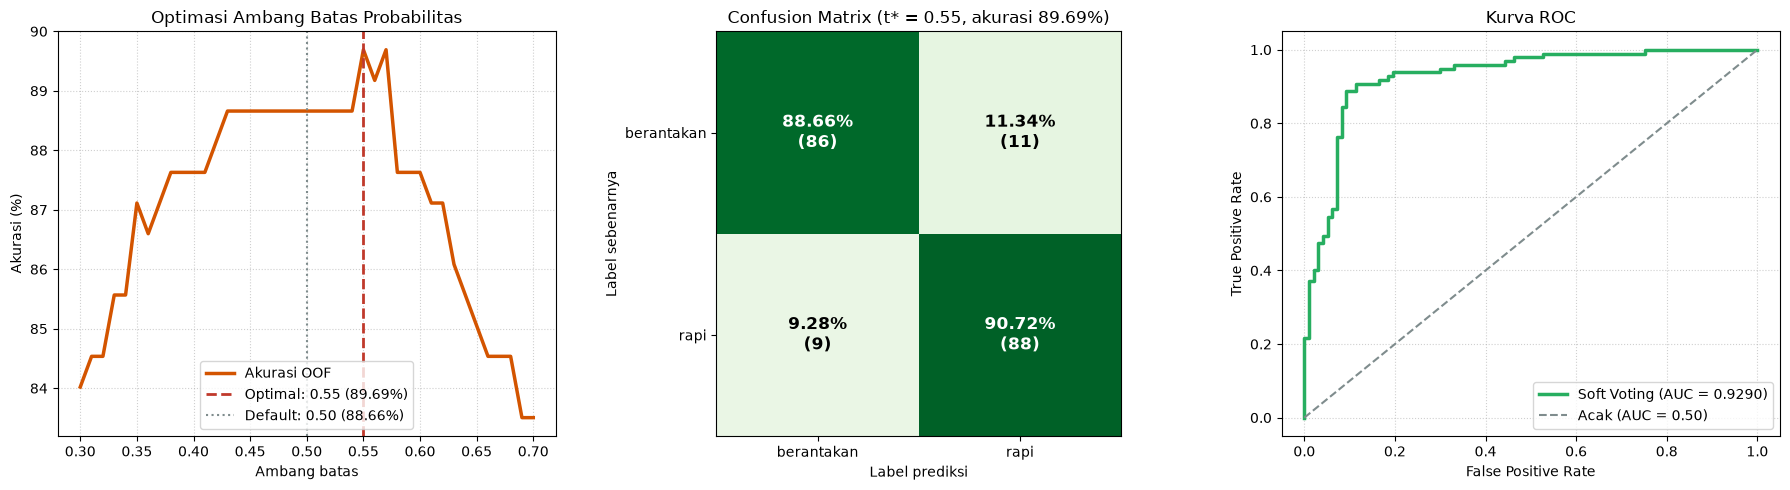

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(thresholds, [a * 100 for a in acc_list], color="#d35400", lw=2.5, label="Akurasi OOF")
axes[0].axvline(best_th, color="#c0392b", ls="--", lw=2, label=f"Optimal: {best_th:.2f} ({best_acc*100:.2f}%)")
axes[0].axvline(0.5, color="#7f8c8d", ls=":", lw=1.5, label=f"Default: 0.50 ({acc_default*100:.2f}%)")
axes[0].set(title="Optimasi Ambang Batas Probabilitas", xlabel="Ambang batas", ylabel="Akurasi (%)")
axes[0].legend(loc="lower center"); axes[0].grid(True, ls=":", alpha=0.6)

cm_norm = cm_opt / cm_opt.sum(axis=1, keepdims=True)
im = axes[1].imshow(cm_norm, cmap="Greens", vmin=0, vmax=1)
for a in range(2):
    for b in range(2):
        axes[1].text(b, a, f"{cm_norm[a, b]:.2%}\n({cm_opt[a, b]})", ha="center", va="center", fontsize=12,
                     fontweight="bold", color="white" if cm_norm[a, b] > 0.5 else "black")
axes[1].set_xticks([0, 1], ["berantakan", "rapi"]); axes[1].set_yticks([0, 1], ["berantakan", "rapi"])
axes[1].set(title=f"Confusion Matrix (t* = {best_th:.2f}, akurasi {best_acc*100:.2f}%)",
            xlabel="Label prediksi", ylabel="Label sebenarnya")

fpr, tpr, _ = roc_curve(y_asli, proba_oof)
axes[2].plot(fpr, tpr, color="#27ae60", lw=2.5, label=f"Soft Voting (AUC = {roc_auc:.4f})")
axes[2].plot([0, 1], [0, 1], color="#7f8c8d", ls="--", lw=1.5, label="Acak (AUC = 0.50)")
axes[2].set(title="Kurva ROC", xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[2].legend(loc="lower right"); axes[2].grid(True, ls=":", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(FOLDER_HASIL, "evaluasi_model.png"), dpi=150, bbox_inches="tight")
plt.show()

---
## Bagian 5: Penyimpanan Model Final ke Satu File Bundle (`.pkl`)
Model ensemble dilatih ulang pada **seluruh sampel augmentasi** (semua citra × 4 variasi), lalu disimpan bersama daftar fitur, ambang batas optimal, dan metadata ke `hasil3/model_terbaik_penataan_sepatu.pkl`. `StandardScaler` sudah berada di dalam `Pipeline`, sehingga ikut tersimpan.

In [7]:
import os
import warnings
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
model_final = buat_ensemble().fit(data[FITUR], (data["kelas"] == "rapi").astype(int))

bundle = {
    "model": model_final,
    "fitur_cols": FITUR,
    "optimal_threshold": best_th,
    "classes": ["berantakan", "rapi"],
    "ukuran": UKURAN,
    "metadata": {
        "citra_asli": int(data["id_citra"].nunique()),
        "total_sampel_latih": len(data),
        "jumlah_fitur": len(FITUR),
        "augmentasi": "4x (baseline, rotate_15, flip_horizontal, adjust_brightness)",
        "model_dasar": ["SVM RBF (w=2)", "Extra Trees (w=2)", "Gradient Boosting (w=1)"],
        "akurasi_cv_default": round(acc_default, 4),
        "akurasi_cv_optimal": round(best_acc, 4),
        "roc_auc": round(roc_auc, 4),
    },
}
joblib.dump(bundle, os.path.join(FOLDER_HASIL, "model_terbaik_penataan_sepatu.pkl"))
print(f"Model ensemble {len(FITUR)} fitur disimpan ke {FOLDER_HASIL}/model_terbaik_penataan_sepatu.pkl")

Model ensemble 53 fitur disimpan ke hasil3/model_terbaik_penataan_sepatu.pkl


---
## Bagian 6: Fungsi Inferensi untuk Prediksi Citra Sepatu Baru
Fungsi `prediksi_citra_sepatu` menerima *path* foto, menjalankan langkah yang **sama persis** dengan pelatihan (resize 256 × 256 → ekstraksi 53 fitur), lalu mengembalikan label dan peluangnya memakai ambang batas optimal yang tersimpan.

In [8]:
import os
import joblib
import pandas as pd

def prediksi_citra_sepatu(path, bundle_path=os.path.join(FOLDER_HASIL, "model_terbaik_penataan_sepatu.pkl")):
    bundle = joblib.load(bundle_path)
    img = baca_citra(path)
    if img is None:
        raise ValueError(f"Tidak dapat membaca citra: {path}")
    x = pd.DataFrame([ekstrak_fitur(preprocessing(img))])[bundle["fitur_cols"]]
    p_rapi = float(bundle["model"].predict_proba(x)[0, 1])
    return {"prediksi": "rapi" if p_rapi >= bundle["optimal_threshold"] else "berantakan",
            "probabilitas_rapi": p_rapi, "probabilitas_berantakan": 1 - p_rapi,
            "ambang_batas": bundle["optimal_threshold"]}

for kelas in KELAS:
    contoh = os.path.join(FOLDER_CITRA, kelas, sorted(os.listdir(os.path.join(FOLDER_CITRA, kelas)))[0])
    h = prediksi_citra_sepatu(contoh)
    print(f"Uji '{contoh}': prediksi = {h['prediksi'].upper()} (P rapi: {h['probabilitas_rapi']:.2%})")

Uji 'citra\rapi\24-003 Rapi 2.jpg': prediksi = RAPI (P rapi: 99.29%)
Uji 'citra\berantakan\24-003 Berantakan 2.jpg': prediksi = BERANTAKAN (P rapi: 0.64%)


### Prediksi Foto Sendiri (Upload)
Jalankan sel di bawah, lalu pilih satu atau beberapa foto. Di Google Colab muncul tombol *Choose Files*; di Jupyter/VS Code muncul jendela pilih file (kadang tersembunyi di belakang jendela VS Code, cek *taskbar*).

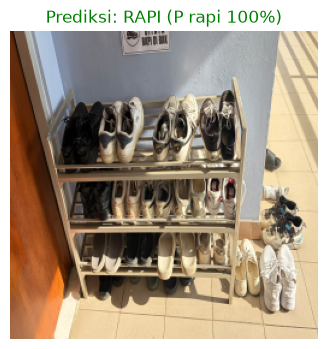

In [9]:
import os
import matplotlib.pyplot as plt

try:
    from google.colab import files
    daftar_foto = list(files.upload().keys())
except ImportError:
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk(); root.withdraw(); root.attributes("-topmost", True)
    daftar_foto = filedialog.askopenfilenames(title="Pilih foto sepatu",
                                              filetypes=[("Gambar", "*.jpg *.jpeg *.png *.bmp *.webp")])
    root.destroy()

for path in daftar_foto:
    h = prediksi_citra_sepatu(path)
    plt.figure(figsize=(4, 4))
    plt.imshow(preprocessing(baca_citra(path)))
    plt.title(f"Prediksi: {h['prediksi'].upper()} (P rapi {h['probabilitas_rapi']:.0%})",
              color="green" if h["prediksi"] == "rapi" else "red")
    plt.axis("off")
    plt.show()

---
# REKAPITULASI EVOLUSI AKURASI PROYEK
## Dari 14 Fitur Tugas hingga 53 Fitur + Augmentasi + Ensemble

Setiap tahap dihitung ulang di sini dengan **protokol yang sama** (10 *fold* yang sama, validasi selalu citra asli), sehingga kenaikan akurasi antar-tahap dapat dibandingkan secara adil. Hasil disimpan ke `hasil3/evolusi_akurasi.csv`.

| Tahap | Fitur | Model | Augmentasi |
| :--- | :--- | :--- | :---: |
| 1 | 14 fitur tugas (RGB + GLCM) | KNN ($k = 5$) | Tidak |
| 2 | 14 fitur tugas | SVM RBF | Tidak |
| 3 | 14 fitur tugas | Weighted Soft Voting | Tidak |
| 4 | 53 fitur | Weighted Soft Voting | Tidak |
| 5 | 53 fitur | Weighted Soft Voting | Ya (4×) |

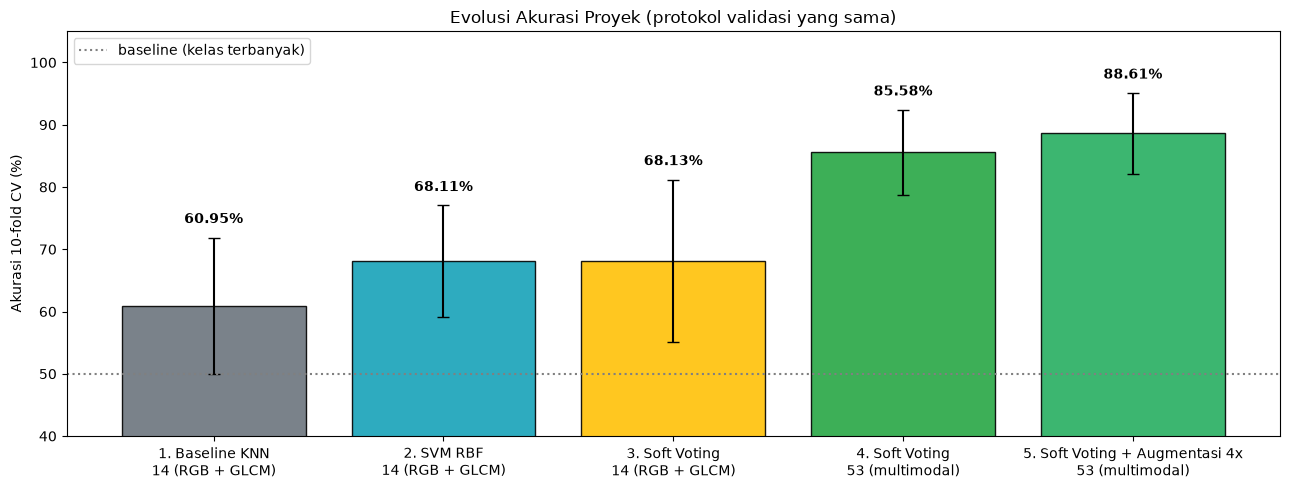

,Tahap,Fitur,Augmentasi,Akurasi,Std,ROC AUC
0,1. Baseline KNN,14 (RGB + GLCM),Tidak,0.6095,0.1094,0.6753
1,2. SVM RBF,14 (RGB + GLCM),Tidak,0.6811,0.0893,0.7493
2,3. Soft Voting,14 (RGB + GLCM),Tidak,0.6813,0.1306,0.7739
3,4. Soft Voting,53 (multimodal),Tidak,0.8558,0.0680,0.9208
4,5. Soft Voting + Augmentasi 4x,53 (multimodal),Ya,0.8861,0.0649,0.9290


In [10]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
FITUR_TUGAS = [f"{s}_{k}" for s in ("mean", "std", "skew") for k in "rgb"] + \
              ["energi", "entropi", "kontras", "korelasi", "homogenitas"]

tahapan = [
    ("1. Baseline KNN", "14 (RGB + GLCM)", lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(5)), FITUR_TUGAS, False),
    ("2. SVM RBF", "14 (RGB + GLCM)", lambda: make_pipeline(StandardScaler(), SVC(C=10, probability=True, random_state=42)), FITUR_TUGAS, False),
    ("3. Soft Voting", "14 (RGB + GLCM)", buat_ensemble, FITUR_TUGAS, False),
    ("4. Soft Voting", "53 (multimodal)", buat_ensemble, FITUR, False),
    ("5. Soft Voting + Augmentasi 4x", "53 (multimodal)", buat_ensemble, FITUR, True),
]
evolusi = []
for nama, fitur_ket, buat, fitur, aug in tahapan:
    log, p = validasi_silang(buat, fitur=fitur, pakai_augmentasi=aug)
    evolusi.append({"Tahap": nama, "Fitur": fitur_ket, "Augmentasi": "Ya" if aug else "Tidak",
                    "Akurasi": log["Akurasi"].mean(), "Std": log["Akurasi"].std(), "ROC AUC": roc_auc_score(y_asli, p)})
df_evolusi = pd.DataFrame(evolusi)
df_evolusi.round(4).to_csv(os.path.join(FOLDER_HASIL, "evolusi_akurasi.csv"), index=False)

fig, ax = plt.subplots(figsize=(13, 5))
warna = ["#6c757d", "#17a2b8", "#ffc107", "#28a745", "#27ae60"]
batang = ax.bar([f"{t}\n{f}" for t, f in zip(df_evolusi["Tahap"], df_evolusi["Fitur"])], df_evolusi["Akurasi"] * 100,
                yerr=df_evolusi["Std"] * 100, capsize=4, color=warna, edgecolor="black", alpha=0.9)
ax.bar_label(batang, labels=[f"{v*100:.2f}%" for v in df_evolusi["Akurasi"]], padding=8, fontweight="bold")
ax.axhline(y_asli.value_counts(normalize=True).max() * 100, color="gray", ls=":", label="baseline (kelas terbanyak)")
ax.set(ylim=(40, 105), ylabel="Akurasi 10-fold CV (%)", title="Evolusi Akurasi Proyek (protokol validasi yang sama)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FOLDER_HASIL, "evolusi_akurasi.png"), dpi=150, bbox_inches="tight")
plt.show()

df_evolusi.round(4)

---
# KOMPARASI METODE KLASIKAL & ENSEMBLE
## Model Tunggal, Bagging, Boosting, Voting (Soft/Hard), dan Stacking

Semua metode diuji dengan **53 fitur + augmentasi** dan protokol 10-fold yang sama. Kolom:
- **Akurasi** dan **F1**: rata-rata 10 *fold* pada ambang 0,5.
- **ROC AUC**: dari peluang *out-of-fold* (Hard Voting tidak menghasilkan peluang, sehingga AUC-nya kosong).

Hasil disimpan ke `hasil3/komparasi_metode.csv` dan `hasil3/komparasi_metode.png`.

KNN (k=5)                                  akurasi  84.55%
SVM RBF                                    akurasi  87.11%
Decision Tree                              akurasi  68.97%
Logistic Regression                        akurasi  76.24%
Naive Bayes                                akurasi  66.39%
Random Forest                              akurasi  79.32%
Extra Trees                                akurasi  84.05%
AdaBoost                                   akurasi  82.05%
Gradient Boosting                          akurasi  83.00%
Weighted Soft Voting (SVM:2, ET:2, GB:1)   akurasi  88.61%
Hard Voting (SVM + ET + GB)                akurasi  85.05%
Stacking (meta: Logistic Regression)       akurasi  88.61%


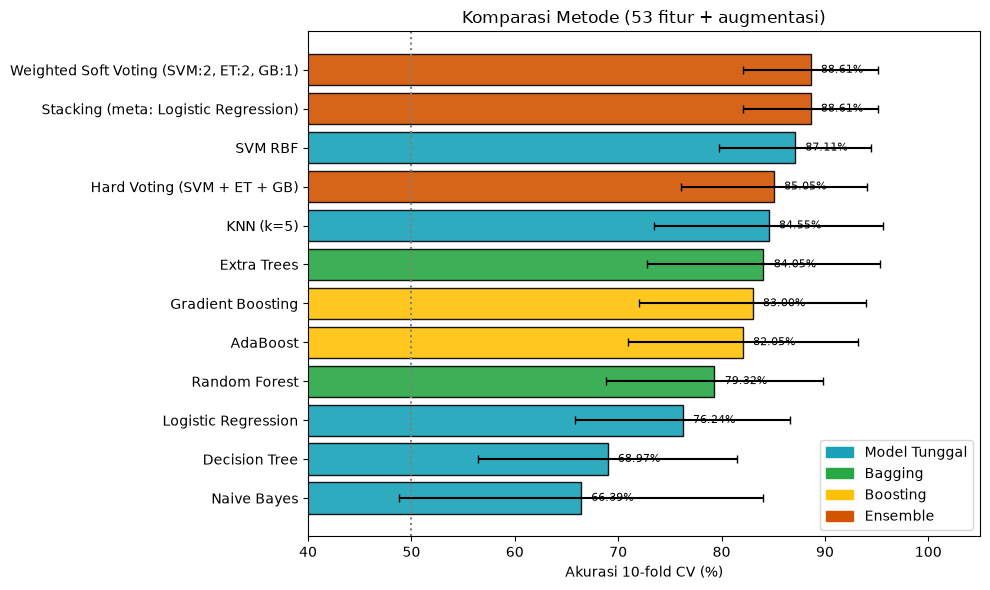

,Kategori,Model,Akurasi,Std,F1,ROC AUC
0,Ensemble,"Weighted Soft Voting (SVM:2, ET:2, GB:1)",0.8861,0.0649,0.8879,0.9290
1,Ensemble,Stacking (meta: Logistic Regression),0.8861,0.0649,0.8879,0.9049
2,Model Tunggal,SVM RBF,0.8711,0.0737,0.8731,0.9185
3,Ensemble,Hard Voting (SVM + ET + GB),0.8505,0.0899,0.8439,NaN
4,Model Tunggal,KNN (k=5),0.8455,0.1108,0.8424,0.9127
5,Bagging,Extra Trees,0.8405,0.1131,0.8297,0.9132
6,Boosting,Gradient Boosting,0.8300,0.1096,0.8294,0.8941
7,Boosting,AdaBoost,0.8205,0.1114,0.8290,0.8752
8,Bagging,Random Forest,0.7932,0.1051,0.7903,0.8783
9,Model Tunggal,Logistic Regression,0.7624,0.1039,0.7675,0.8345


In [11]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)

def dasar():
    return [("svm", SVC(kernel="rbf", C=10.0, probability=True, random_state=42)),
            ("et", ExtraTreesClassifier(n_estimators=150, max_features="log2", random_state=42)),
            ("gb", GradientBoostingClassifier(n_estimators=120, learning_rate=0.08, max_depth=4, subsample=0.75, random_state=42))]

metode = {
    ("Model Tunggal", "KNN (k=5)"): lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    ("Model Tunggal", "SVM RBF"): lambda: make_pipeline(StandardScaler(), SVC(C=10, probability=True, random_state=42)),
    ("Model Tunggal", "Decision Tree"): lambda: DecisionTreeClassifier(max_depth=8, random_state=42),
    ("Model Tunggal", "Logistic Regression"): lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    ("Model Tunggal", "Naive Bayes"): lambda: make_pipeline(StandardScaler(), GaussianNB()),
    ("Bagging", "Random Forest"): lambda: RandomForestClassifier(n_estimators=200, random_state=42),
    ("Bagging", "Extra Trees"): lambda: ExtraTreesClassifier(n_estimators=150, max_features="log2", random_state=42),
    ("Boosting", "AdaBoost"): lambda: AdaBoostClassifier(n_estimators=200, random_state=42),
    ("Boosting", "Gradient Boosting"): lambda: GradientBoostingClassifier(n_estimators=120, learning_rate=0.08, max_depth=4, subsample=0.75, random_state=42),
    ("Ensemble", "Weighted Soft Voting (SVM:2, ET:2, GB:1)"): buat_ensemble,
    ("Ensemble", "Hard Voting (SVM + ET + GB)"): lambda: make_pipeline(StandardScaler(), VotingClassifier(dasar(), voting="hard")),
    ("Ensemble", "Stacking (meta: Logistic Regression)"): lambda: make_pipeline(StandardScaler(), StackingClassifier(
        dasar(), final_estimator=LogisticRegression(max_iter=5000), cv=5)),
}

baris = []
for (kategori, nama), buat in metode.items():
    log, p = validasi_silang(buat)
    baris.append({"Kategori": kategori, "Model": nama, "Akurasi": log["Akurasi"].mean(), "Std": log["Akurasi"].std(),
                  "F1": log["F1"].mean(), "ROC AUC": roc_auc_score(y_asli, p) if p.notna().all() else np.nan})
    print(f"{nama:42} akurasi {baris[-1]['Akurasi']*100:6.2f}%")

komparasi = pd.DataFrame(baris).sort_values("Akurasi", ascending=False).reset_index(drop=True)
komparasi.round(4).to_csv(os.path.join(FOLDER_HASIL, "komparasi_metode.csv"), index=False)

fig, ax = plt.subplots(figsize=(10, 6))
urut = komparasi.iloc[::-1]
warna = {"Model Tunggal": "#17a2b8", "Bagging": "#28a745", "Boosting": "#ffc107", "Ensemble": "#d35400"}
ax.barh(urut["Model"], urut["Akurasi"] * 100, xerr=urut["Std"] * 100, capsize=3,
        color=[warna[k] for k in urut["Kategori"]], edgecolor="black", alpha=0.9)
for yy, v in enumerate(urut["Akurasi"]):
    ax.text(v * 100 + 1, yy, f"{v*100:.2f}%", va="center", fontsize=8)
ax.axvline(y_asli.value_counts(normalize=True).max() * 100, color="gray", ls=":")
ax.set(xlim=(40, 105), xlabel="Akurasi 10-fold CV (%)", title="Komparasi Metode (53 fitur + augmentasi)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in warna.values()], labels=list(warna), loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FOLDER_HASIL, "komparasi_metode.png"), dpi=150, bbox_inches="tight")
plt.show()

komparasi.round(4)

In [12]:
import os
import pandas as pd

terbaik = komparasi.iloc[0]
ringkasan = pd.DataFrame([
    ("Citra asli / sampel augmentasi", f"{data['id_citra'].nunique()} / {len(data)}"),
    ("Distribusi kelas (citra asli)", ", ".join(f"{k} {v}" for k, v in asli["kelas"].value_counts().items())),
    ("Jumlah fitur", f"{len(FITUR)} (14 fitur tugas + {len(FITUR) - 14} fitur tambahan)"),
    ("Protokol validasi", "10-fold stratified pada citra asli; latih = 4 variasi, validasi = citra asli"),
    ("Akurasi tahap 1 (KNN, 14 fitur)", f"{df_evolusi.loc[0, 'Akurasi']:.2%}"),
    ("Akurasi Soft Voting 14 fitur", f"{df_evolusi.loc[2, 'Akurasi']:.2%}"),
    ("Akurasi Soft Voting 53 fitur", f"{df_evolusi.loc[3, 'Akurasi']:.2%}"),
    ("Akurasi Soft Voting 53 fitur + augmentasi", f"{df_evolusi.loc[4, 'Akurasi']:.2%} ± {df_evolusi.loc[4, 'Std']:.2%}"),
    ("ROC AUC Soft Voting 53 fitur + augmentasi", f"{df_evolusi.loc[4, 'ROC AUC']:.4f}"),
    ("Ambang optimal / akurasi pada ambang itu", f"{best_th:.2f} / {best_acc:.2%} (optimis, dipilih dari data yang sama)"),
    ("Metode terbaik (komparasi)", f"{terbaik['Model']}: {terbaik['Akurasi']:.2%}"),
    ("File model", f"{FOLDER_HASIL}/model_terbaik_penataan_sepatu.pkl"),
], columns=["Aspek", "Hasil"])
ringkasan.to_csv(os.path.join(FOLDER_HASIL, "ringkasan.csv"), index=False)
pd.set_option("display.max_colwidth", None)
ringkasan

,Aspek,Hasil
0,Citra asli / sampel augmentasi,194 / 776
1,Distribusi kelas (citra asli),"rapi 97, berantakan 97"
2,Jumlah fitur,53 (14 fitur tugas + 39 fitur tambahan)
3,Protokol validasi,"10-fold stratified pada citra asli; latih = 4 variasi, validasi = citra asli"
4,"Akurasi tahap 1 (KNN, 14 fitur)",60.95%
5,Akurasi Soft Voting 14 fitur,68.13%
6,Akurasi Soft Voting 53 fitur,85.58%
7,Akurasi Soft Voting 53 fitur + augmentasi,88.61% ± 6.49%
8,ROC AUC Soft Voting 53 fitur + augmentasi,0.9290
9,Ambang optimal / akurasi pada ambang itu,"0.55 / 89.69% (optimis, dipilih dari data yang sama)"
